# Phase 2: Data Processing and Cleaning

### Objective

##### To inspect, process, and clean the dataset by identifying and handling missing values, duplicate records, inconsistent data, and incorrect data formats to improve data quality and ensure accuracy for further analysis. The original dataset will be preserved without making any changes. All data cleaning and preprocessing operations will be performed on a separate working copy, ensuring that the original data remains safe and unchanged throughout the process.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load the raw dataset into a dataframe
df = pd.read_excel(r"C:\ssk\Data analytics entri\main project\Road Accident Dataset.xlsx")

In [3]:
# Create a separate working copy for all data processing and cleaning operations
df_Cleaned = df.copy()

print("Dataset loaded successfully!")
print("Number of rows:", df_Cleaned.shape[0])
print("Number of columns:", df_Cleaned.shape[1])
df_Cleaned.head()

Dataset loaded successfully!
Number of rows: 50008
Number of columns: 20


,Accident_Index,Accident Date,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_(District),Carriageway_Hazards,Longitude,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
0,1,2022-10-01,Auto traffic signal,T or staggered junction,Minor,51.485108,Daylight,Hamar Jajab,NaN,-0.373240,2,2,Metropolitan Police,Wet or damp,Single carriageway,30,0.572917,Urban,Raining no high winds,Car
1,2,2022-07-06,Auto traffic signal,Crossroads,Minor,51.481508,Darkness - lights lit,Hamar Jajab,NaN,-0.347301,2,2,Metropolitan Police,Dry,Single carriageway,30,0.959722,Urban,Fine no high winds,Car
2,3,2022-07-08,Auto traffic signal,Crossroads,Minor,51.483206,Daylight,Hamar Jajab,NaN,-0.327508,1,2,Metropolitan Police,Dry,Dual carriageway,40,0.309028,Urban,Fine no high winds,Bus or coach (17 or more pass seats)
3,4,2022-09-21,Auto traffic signal,T or staggered junction,Major,51.446757,Daylight,Hamar Jajab,NaN,-0.409430,1,2,Metropolitan Police,Dry,Single carriageway,30,0.380556,Urban,Fine no high winds,Bus or coach (17 or more pass seats)
4,5,2022-10-03,Data missing or out of range,Not at junction or within 20 metres,Minor,51.435504,Darkness - lights lit,Hamar Jajab,NaN,-0.382197,1,2,Metropolitan Police,Wet or damp,Dual carriageway,50,0.125000,Urban,Raining no high winds,Car


## Checking and Handling Missing Values

#### Check missing values before cleaning

In [4]:
# Count missing values in each column
missing_values = df_Cleaned.isnull().sum()
missing_values = missing_values[missing_values > 0]

print("Columns containing missing values:")
print(missing_values)

Columns containing missing values:
Accident_Severity          2
Carriageway_Hazards    49320
Urban_or_Rural_Area        2
dtype: int64


#### Handle missing values

In [5]:
# Fill missing Accident_Severity with mode

severity_mode = df_Cleaned['Accident_Severity'].mode()[0]

df_Cleaned['Accident_Severity'] = (
    df_Cleaned['Accident_Severity'].fillna(severity_mode)
)

In [6]:
# Fill missing Carriageway_Hazards with Unknown

df_Cleaned['Carriageway_Hazards'] = (
    df_Cleaned['Carriageway_Hazards'].fillna('Unknown / Not Reported')
)

In [7]:
#  Fill missing Urban_or_Rural_Area with mode

area_mode = df_Cleaned['Urban_or_Rural_Area'].mode()[0]

df_Cleaned['Urban_or_Rural_Area'] = (
    df_Cleaned['Urban_or_Rural_Area'].fillna(area_mode)
)

print("Missing values handled successfully!")

Missing values handled successfully!


#### Verify missing values after cleaning

In [8]:
# Check missing values after imputation

print("Missing values after cleaning:")
print(df_Cleaned.isnull().sum())

print("\nTotal missing values:",
      df_Cleaned.isnull().sum().sum())

Missing values after cleaning:
Accident_Index                0
Accident Date                 0
Junction_Control              0
Junction_Detail               0
Accident_Severity             0
Latitude                      0
Light_Conditions              0
Local_Authority_(District)    0
Carriageway_Hazards           0
Longitude                     0
Number_of_Casualties          0
Number_of_Vehicles            0
Police_Force                  0
Road_Surface_Conditions       0
Road_Type                     0
Speed_limit                   0
Time                          0
Urban_or_Rural_Area           0
Weather_Conditions            0
Vehicle_Type                  0
dtype: int64

Total missing values: 0


## Checking and Handling Duplicate Records

### Identify duplicate records

In [9]:
# Identify duplicate Accident_Index records

duplicate_records = df_Cleaned[
    df_Cleaned.duplicated(
        subset=['Accident_Index'],
        keep=False
    )
].sort_values('Accident_Index')

print("Duplicate records:")
display(duplicate_records)

Duplicate records:


,Accident_Index,Accident Date,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_(District),Carriageway_Hazards,Longitude,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
4,5,2022-10-03,Data missing or out of range,Not at junction or within 20 metres,Minor,51.435504,Darkness - lights lit,Hamar Jajab,Unknown / Not Reported,-0.382197,1,2,Metropolitan Police,Wet or damp,Dual carriageway,50,0.125000,Urban,Raining no high winds,Car
12,5,2022-10-03,Data missing or out of range,Not at junction or within 20 metres,Minor,51.435504,Darkness - lights lit,Hamar Jajab,Unknown / Not Reported,-0.382197,1,2,Metropolitan Police,Wet or damp,Dual carriageway,50,0.125000,Urban,Raining no high winds,Car
13,6,2022-10-05,Auto traffic signal,Crossroads,Mina,51.447113,Darkness - lights lit,Hamar Jajab,Unknown / Not Reported,-0.409130,2,3,Metropolitan Police,Dry,Single carriageway,30,0.805556,Urban,Fine no high winds,Car
5,6,2022-10-05,Auto traffic signal,Crossroads,Mina,51.447113,Darkness - lights lit,Hamar Jajab,Unknown / Not Reported,-0.409130,2,3,Metropolitan Police,Dry,Single carriageway,30,0.805556,Urban,Fine no high winds,Car
6,7,2022-10-04,Give way or uncontrolled,T or staggered junction,Mina,51.492446,Daylight,Hamar Jajab,Unknown / Not Reported,-0.264074,1,2,Metropolitan Police,Wet or damp,Single carriageway,30,0.664583,Urban,Fine no high winds,Car
14,7,2022-10-04,Give way or uncontrolled,T or staggered junction,Mina,51.492446,Daylight,Hamar Jajab,Unknown / Not Reported,-0.264074,1,2,Metropolitan Police,Wet or damp,Single carriageway,30,0.664583,Urban,Fine no high winds,Car
15,8,2022-10-05,Give way or uncontrolled,T or staggered junction,Mina,51.481999,Daylight,Hamar Jajab,Unknown / Not Reported,-0.324816,1,2,Metropolitan Police,Dry,Single carriageway,30,0.333333,Urban,Fine no high winds,Car
7,8,2022-10-05,Give way or uncontrolled,T or staggered junction,Mina,51.481999,Daylight,Hamar Jajab,Unknown / Not Reported,-0.324816,1,2,Metropolitan Police,Dry,Single carriageway,30,0.333333,Urban,Fine no high winds,Car
16,9,2022-09-28,Auto traffic signal,Crossroads,Mina,51.472153,Daylight,Hamar Jajab,Unknown / Not Reported,-0.405523,1,2,Metropolitan Police,Dry,Dual carriageway,40,0.333333,Urban,Fine no high winds,Motorcycle 125cc and under
8,9,2022-09-28,Auto traffic signal,Crossroads,Mina,51.472153,Daylight,Hamar Jajab,Unknown / Not Reported,-0.405523,1,2,Metropolitan Police,Dry,Dual carriageway,40,0.333333,Urban,Fine no high winds,Motorcycle 125cc and under


### Check whether duplicate IDs have conflicting information

In [10]:
# Check whether duplicate Accident_Index values
# contain different records

duplicate_groups = df_Cleaned[
    df_Cleaned.duplicated(
        subset=['Accident_Index'],
        keep=False
    )
]

conflicting_ids = (
    duplicate_groups.groupby('Accident_Index')
    .apply(lambda group: len(group.drop_duplicates()) > 1)
)

print("Number of duplicate IDs with conflicting records:",
      conflicting_ids.sum())

Number of duplicate IDs with conflicting records: 0


### Remove duplicate records

In [11]:
# Remove duplicate records based on Accident_Index

before_removal = len(df_Cleaned)

df_Cleaned = df_Cleaned.drop_duplicates(
    subset=['Accident_Index'],
    keep='first'
)

after_removal = len(df_Cleaned)

removed_records = before_removal - after_removal

print("Duplicate records removed:", removed_records)
print("Records before cleaning:", before_removal)
print("Records after cleaning:", after_removal)

Duplicate records removed: 8
Records before cleaning: 50008
Records after cleaning: 50000


#### Verify duplicate removal

In [12]:
# Check remaining duplicate records

print("Remaining full duplicate rows:",
      df_Cleaned.duplicated().sum())

print("Remaining duplicate Accident_Index values:",
      df_Cleaned['Accident_Index'].duplicated().sum())

Remaining full duplicate rows: 0
Remaining duplicate Accident_Index values: 0


## Checking and Handling Data Types

In [13]:
# Inspect data types of all columns
df_Cleaned.info()

<class 'pandas.DataFrame'>
Index: 50000 entries, 0 to 50007
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Accident_Index              50000 non-null  int64         
 1   Accident Date               50000 non-null  datetime64[us]
 2   Junction_Control            50000 non-null  str           
 3   Junction_Detail             50000 non-null  str           
 4   Accident_Severity           50000 non-null  str           
 5   Latitude                    50000 non-null  float64       
 6   Light_Conditions            50000 non-null  str           
 7   Local_Authority_(District)  50000 non-null  str           
 8   Carriageway_Hazards         50000 non-null  str           
 9   Longitude                   50000 non-null  float64       
 10  Number_of_Casualties        50000 non-null  int64         
 11  Number_of_Vehicles          50000 non-null  int64         
 12  Police

In [14]:
# Check sample date values before conversion
print(df_Cleaned['Accident Date'].head(10))

0   2022-10-01
1   2022-07-06
2   2022-07-08
3   2022-09-21
4   2022-10-03
5   2022-10-05
6   2022-10-04
7   2022-10-05
8   2022-09-28
9   2022-07-24
Name: Accident Date, dtype: datetime64[us]


In [15]:
# Convert 'Accident Date' to standard datetime format
df_Cleaned['Accident Date'] = pd.to_datetime(
    df_Cleaned['Accident Date'],
    errors='coerce'
)

In [16]:
# Verify conversion and check for invalid or unparseable dates
print("Datatype after conversion:", df_Cleaned['Accident Date'].dtype)
print("Invalid/Null dates after conversion:", df_Cleaned['Accident Date'].isnull().sum())

Datatype after conversion: datetime64[us]
Invalid/Null dates after conversion: 0


## Checking Inconsistent Values and Text Standardisation

In [17]:
# Identify categorical columns

categorical_columns = df_Cleaned.select_dtypes(
    include=['object', 'str']
).columns

In [18]:
# Remove unwanted spaces from categorical values

for col in categorical_columns:
    df_Cleaned[col] = df_Cleaned[col].str.strip()

print("Unwanted spaces removed successfully!")

Unwanted spaces removed successfully!


In [19]:
# Correct inconsistent categorical values

df_Cleaned['Accident_Severity'] = (
    df_Cleaned['Accident_Severity'].replace({
        'Mina': 'Minor'
    })
)

df_Cleaned['Junction_Control'] = (
    df_Cleaned['Junction_Control'].replace({
        'Auto traffic sigl': 'Auto traffic signal'
    })
)

df_Cleaned['Road_Type'] = (
    df_Cleaned['Road_Type'].replace({
        'Fine no high winds': 'Unknown / Not Reported'
    })
)

print("Inconsistent values corrected successfully!")

Inconsistent values corrected successfully!


In [20]:
# Verify corrected categorical values

columns_to_check = [
    'Accident_Severity',
    'Junction_Control',
    'Road_Type'
]

for col in columns_to_check:
    print(f"\nValue counts for {col}:")
    print(df_Cleaned[col].value_counts())


Value counts for Accident_Severity:
Accident_Severity
Minor    43100
Major     6455
Fatal      445
Name: count, dtype: int64

Value counts for Junction_Control:
Junction_Control
Give way or uncontrolled               25451
Data missing or out of range           14429
Auto traffic signal                     6210
Not at junction or within 20 metres     3581
Stop sign                                257
Authorised person                         72
Name: count, dtype: int64

Value counts for Road_Type:
Road_Type
Single carriageway        37057
Dual carriageway           8032
Roundabout                 3251
One way street              972
Slip road                   542
Unknown / Not Reported      146
Name: count, dtype: int64


In [21]:
# Display unique values in categorical columns

for col in categorical_columns:
    print(f"\nUnique values in {col}:")
    print(df_Cleaned[col].unique())


Unique values in Junction_Control:
<ArrowStringArray>
[                'Auto traffic signal',        'Data missing or out of range',
            'Give way or uncontrolled',                   'Authorised person',
                           'Stop sign', 'Not at junction or within 20 metres']
Length: 6, dtype: str

Unique values in Junction_Detail:
<ArrowStringArray>
[            'T or staggered junction',                          'Crossroads',
 'Not at junction or within 20 metres',           'Private drive or entrance',
                          'Roundabout',                     'Mini-roundabout',
                           'Slip road',   'More than 4 arms (not roundabout)',
                      'Other junction']
Length: 9, dtype: str

Unique values in Accident_Severity:
<ArrowStringArray>
['Minor', 'Major', 'Fatal']
Length: 3, dtype: str

Unique values in Light_Conditions:
<ArrowStringArray>
[                   'Daylight',       'Darkness - lights lit',
      'Darkness - no lighting'

In [22]:
# Check whether the identified inconsistent values remain

print("Mina remaining:",
      (df_Cleaned['Accident_Severity'] == 'Mina').sum())

print("Auto traffic sigl remaining:",
      (df_Cleaned['Junction_Control'] == 'Auto traffic sigl').sum())

print("Incorrect Road_Type remaining:",
      (df_Cleaned['Road_Type'] == 'Fine no high winds').sum())

Mina remaining: 0
Auto traffic sigl remaining: 0
Incorrect Road_Type remaining: 0


### Statistical Summary of Numerical Columns

In [23]:
# Generate statistical descriptions for numerical features
df_Cleaned[['Number_of_Casualties', 'Number_of_Vehicles', 'Speed_limit']].describe()

,Number_of_Casualties,Number_of_Vehicles,Speed_limit
count,50000.000000,50000.000000,50000.000000
mean,1.401360,1.834200,36.523200
std,0.887967,0.712124,12.655555
min,1.000000,1.000000,20.000000
25%,1.000000,1.000000,30.000000
50%,1.000000,2.000000,30.000000
75%,2.000000,2.000000,40.000000
max,40.000000,19.000000,70.000000


### Checking Negative and Zero Values

In [24]:
# Check for negative values in casualty and vehicle counts
print("Negative casualties:", (df_Cleaned['Number_of_Casualties'] < 0).sum())
print("Negative vehicles:", (df_Cleaned['Number_of_Vehicles'] < 0).sum())
print("Negative speed limits:", (df_Cleaned['Speed_limit'] < 0).sum())

Negative casualties: 0
Negative vehicles: 0
Negative speed limits: 0


In [25]:
# Check for zero values where counts must be at least 1
print("Zero casualties:", (df_Cleaned['Number_of_Casualties'] == 0).sum())
print("Zero vehicles:", (df_Cleaned['Number_of_Vehicles'] == 0).sum())

Zero casualties: 0
Zero vehicles: 0


## Outlier Detection Using the Interquartile Range (IQR) Method

In [26]:
# Check outliers for numerical features using IQR
for col in ['Number_of_Casualties', 'Number_of_Vehicles', 'Speed_limit']:
    Q1 = df_Cleaned[col].quantile(0.25)
    Q3 = df_Cleaned[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    
    outliers = df_Cleaned[
        (df_Cleaned[col] < lower_limit) | 
        (df_Cleaned[col] > upper_limit)
    ]
    
    print(f"\nOutliers in {col}: {len(outliers)}")
    print(f"Lower limit: {lower_limit}, Upper limit: {upper_limit}")


Outliers in Number_of_Casualties: 1695
Lower limit: -0.5, Upper limit: 3.5

Outliers in Number_of_Vehicles: 1054
Lower limit: -0.5, Upper limit: 3.5

Outliers in Speed_limit: 7854
Lower limit: 15.0, Upper limit: 55.0


## Data Cleaning – Final Summary

In [27]:
# Final review of cleaned dataset structure
df_Cleaned.info()

<class 'pandas.DataFrame'>
Index: 50000 entries, 0 to 50007
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Accident_Index              50000 non-null  int64         
 1   Accident Date               50000 non-null  datetime64[us]
 2   Junction_Control            50000 non-null  str           
 3   Junction_Detail             50000 non-null  str           
 4   Accident_Severity           50000 non-null  str           
 5   Latitude                    50000 non-null  float64       
 6   Light_Conditions            50000 non-null  str           
 7   Local_Authority_(District)  50000 non-null  str           
 8   Carriageway_Hazards         50000 non-null  str           
 9   Longitude                   50000 non-null  float64       
 10  Number_of_Casualties        50000 non-null  int64         
 11  Number_of_Vehicles          50000 non-null  int64         
 12  Police

# Final Summary – Data Preprocessing and Cleaning

### 1. Overview

The data preprocessing and cleaning phase was carried out to improve the quality, consistency, and reliability of the Road Accident Dataset before proceeding with exploratory data analysis (EDA).

The original dataset contained **50,008 records and 20 columns**. A separate working copy (`df_Cleaned`) was created to ensure that the original dataset remained unchanged throughout the preprocessing process.

### 2. Data Cleaning Activities

The following preprocessing activities were performed or identified during the data quality assessment:

**A. Missing Value Analysis**

Missing values were identified in three columns:

- `Accident_Severity`: 2 missing values.
- `Carriageway_Hazards`: 49,320 missing values.
- `Urban_or_Rural_Area`: 2 missing values.

Mode imputation was selected for the two columns with very few missing values. The missing values in `Carriageway_Hazards` were assigned an appropriate category, `Unknown / Not Reported`, to preserve the available accident records without making unsupported assumptions.

**B. Duplicate Record Identification**

A total of 8 duplicate records were identified. Duplicate entries were also found in the `Accident_Index` column, which serves as the unique accident identifier.

The recommended approach is to retain one valid record for each accident after checking for conflicting information and remove confirmed duplicate records.

**C. Data Type Verification**

The data types of all 20 columns were examined. The `Accident Date` column was verified and converted using Pandas `to_datetime()`.

No invalid or unparseable dates were identified after conversion.

**D. Inconsistent Value Identification**

Categorical columns were examined to identify inconsistent entries and spelling errors.

Some examples identified include:

- `Mina` instead of `Minor` in `Accident_Severity`.
- `Auto traffic sigl` instead of `Auto traffic signal` in `Junction_Control`.
- `Fine no high winds` appearing as an unusual category in `Road_Type`.

These values require standardisation to ensure consistency during analysis.

**E. Numerical Data Validation**

Numerical columns were checked for negative and zero values.

The analysis confirmed that:
- No negative casualty counts were identified.
- No negative vehicle counts were identified.
- No negative speed limits were identified.
- No zero casualty or vehicle counts were identified.

**F. Outlier Detection**

The Interquartile Range (IQR) method was applied to identify potential outliers in numerical columns.

The following observations were identified:

| Column | Potential outliers |
|---|---:|
| Number_of_Casualties | 1,695 |
| Number_of_Vehicles | 1,054 |
| Speed_limit | 7,854 |

These observations were flagged for further investigation rather than automatically removed, as they may represent genuine accident scenarios.

### 3. Conclusion

The data preprocessing and cleaning phase helped identify important data quality issues, including missing values, duplicate records, inconsistent categorical entries, and potential numerical outliers.

Appropriate cleaning methods were selected to address these issues while preserving meaningful accident information. Special attention was given to maintaining the integrity of the original dataset and avoiding unnecessary deletion of records.

The preprocessing process establishes a foundation for reliable exploratory data analysis and further investigation of road accident patterns, accident severity, environmental conditions, vehicle types, and road safety factors.

The next phase will focus on Exploratory Data Analysis (EDA), where visualisation and statistical techniques will be used to identify meaningful patterns, trends, and insights from the road accident data.

# Phase 3:Exploratory Data Analysis(EDA)

### Objective
To systematically explore the cleaned road accident dataset (`df_Cleaned`, comprising 50,000 records across 20 variables) using statistical summaries and visual analytics across **Univariate**, **Bivariate**, and **Multivariate** dimensions. This phase aims to uncover temporal patterns, high-risk road infrastructures, environmental triggers, and severity drivers to generate actionable road safety insights.

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [29]:
# Set overall visualization style
sns.set_theme(style="whitegrid")

In [32]:
# Extract temporal features from 'Accident Date' and 'Time' for deeper EDA
df_Cleaned['Year'] = df_Cleaned['Accident Date'].dt.year
df_Cleaned['Month'] = df_Cleaned['Accident Date'].dt.month_name()
df_Cleaned['Month_Num'] = df_Cleaned['Accident Date'].dt.month
df_Cleaned['Day_of_Week'] = df_Cleaned['Accident Date'].dt.day_name()
# Convert Excel fractional time (0 to 1) into 24-hour format
df_Cleaned['Hour'] = (df_Cleaned['Time'] * 24).astype(int)

In [33]:
# 1. Numerical Statistical Summary
display(df_Cleaned[['Number_of_Casualties', 'Number_of_Vehicles', 'Speed_limit', 'Hour']].describe())

,Number_of_Casualties,Number_of_Vehicles,Speed_limit,Hour
count,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.401360,1.834200,36.523200,13.619100
std,0.887967,0.712124,12.655555,5.029859
min,1.000000,1.000000,20.000000,0.000000
25%,1.000000,1.000000,30.000000,10.000000
50%,1.000000,2.000000,30.000000,14.000000
75%,2.000000,2.000000,40.000000,17.000000
max,40.000000,19.000000,70.000000,23.000000


In [34]:
# 2. Categorical Statistical Summary
display(df_Cleaned.select_dtypes(include=['object', 'str']).describe())

,Junction_Control,Junction_Detail,Accident_Severity,Light_Conditions,Local_Authority_(District),Carriageway_Hazards,Police_Force,Road_Surface_Conditions,Road_Type,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type,Month,Day_of_Week
count,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000
unique,6,9,3,5,7,6,15,5,6,2,8,15,12,7
top,Give way or uncontrolled,Not at junction or within 20 metres,Minor,Daylight,Wadajir,Unknown / Not Reported,West Midlands,Dry,Single carriageway,Urban,Fine no high winds,Car,November,Saturday
freq,25451,17993,43100,37517,19761,49312,6216,33582,37057,37360,41051,38816,4791,7888


#### Statistical Summary Insights
* **Casualties & Vehicles:** While the median and 75th percentile for `Number_of_Casualties` sit at **1.0** and **2.0** respectively (reflecting that most collisions involve one or two victims), the maximum reaches **40 casualties**, capturing major multi-vehicle pileups or public transit incidents. Similarly, `Number_of_Vehicles` averages **1.83** with a median of **2.0**, peaking at **19 vehicles**.
* **Speed Limits:** `Speed_limit` ranges from **20 mph to 70 mph**, with a median of **30 mph** and a mean of **36.52 mph**, confirming that the majority of recorded collisions occur in lower-speed urban or residential zones.
* **Categorical Dominance:** `Minor` emerges as the most frequent `Accident_Severity` (**43,100 occurrences**), `Car` dominates `Vehicle_Type`, and `Single carriageway` is the most common `Road_Type` (**37,057 occurrences**).

## Univariate Analysis (Single-Variable Exploration)
#### Focuses on understanding individual feature distributions, frequencies, and spreads in isolation.

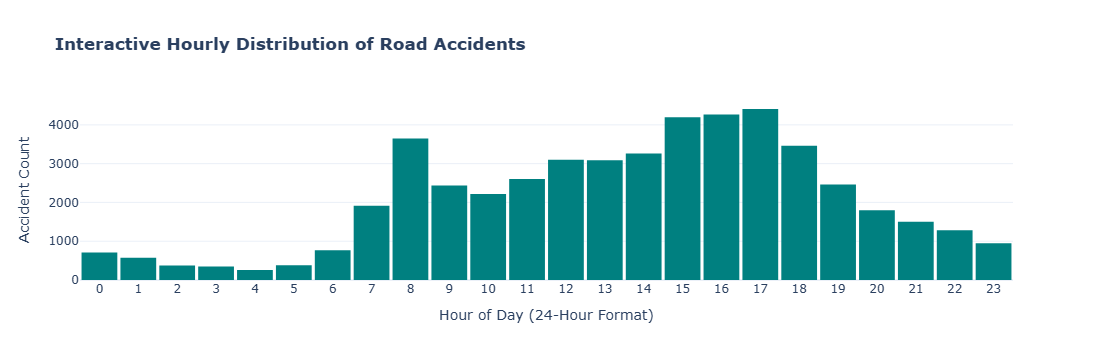

In [35]:
# Objective: Examine the hourly distribution of accidents across a 24-hour cycle.
fig = px.histogram(
    df_Cleaned,
    x='Hour',
    nbins=24,
    title='<b>Interactive Hourly Distribution of Road Accidents</b>',
    labels={'Hour': 'Hour of Day (0 - 23)', 'count': 'Number of Accidents'},
    color_discrete_sequence=['teal']
)

fig.update_layout(
    xaxis_title='Hour of Day (24-Hour Format)',
    yaxis_title='Accident Count',
    bargap=0.08,
    template='plotly_white',
    xaxis=dict(tickmode='linear', tick0=0, dtick=1)
)

fig.show()

**Objective:** To identify peak high-risk hours of the day when road collisions occur most frequently.

**Analysis:**
* **Bimodal Commuter Peaks:** The distribution exhibits two distinct spikes aligned with daily rush hours—a morning commute surge between **08:00 and 09:00**, followed by a substantially larger evening rush-hour peak between **16:00 and 18:00** (peaking sharply at 17:00).
* **Overnight Lull:** Accident frequency drops to its lowest levels between **01:00 and 05:00**, directly mirroring lower overall traffic volume during late-night hours.

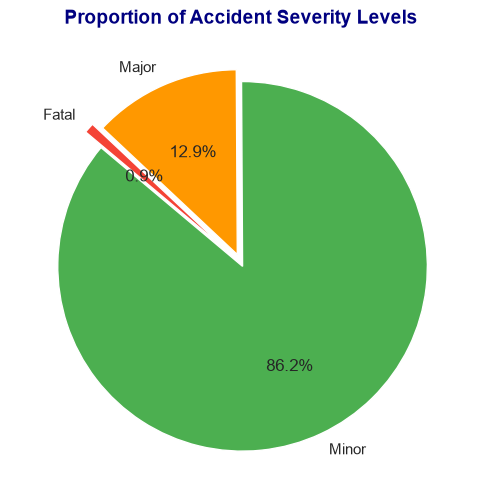

In [36]:
# Objective: Assess the proportion of Minor, Major, and Fatal accidents in the dataset.
plt.figure(figsize=(8, 6))
severity_counts = df_Cleaned['Accident_Severity'].value_counts()
plt.pie(
    severity_counts,
    labels=severity_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#4CAF50', '#FF9800', '#F44336'],
    explode=(0.02, 0.05, 0.1)
)
plt.title('Proportion of Accident Severity Levels', color='navy', fontsize=14, fontweight='bold')
plt.show()

**Objective:** To evaluate the overall severity breakdown of reported traffic collisions.

**Analysis:**
* **Minor Collisions Dominate Catalog Volume (86.2%):** Over four-fifths of all recorded incidents result in minor injuries or property damage, while **Major** accidents account for **12.9%** (6,455 cases).
* **Fatal Minority (0.9%):** Fatal accidents represent less than 1% (445 cases) of total incidents, underscoring a strong class imbalance typical of real-world road safety records.

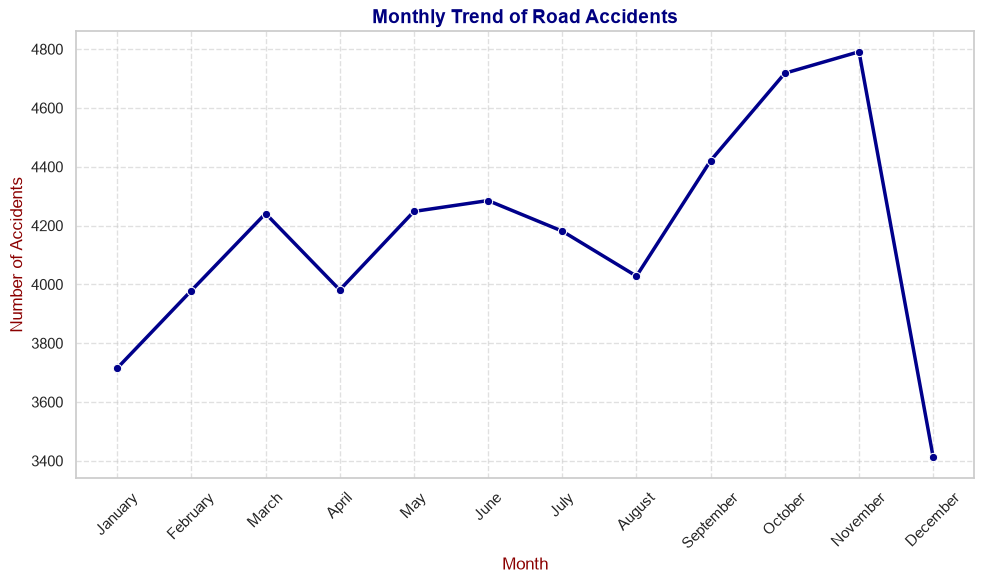

In [37]:
# Objective: Track seasonal fluctuations in accident frequency across calendar months.
monthly_counts = df_Cleaned.groupby(['Month_Num', 'Month']).size().reset_index(name='Count')

plt.figure(figsize=(10, 6))
sns.lineplot(data=monthly_counts, x='Month', y='Count', marker='o', color='darkblue', linewidth=2.5)
plt.title('Monthly Trend of Road Accidents', color='navy', fontsize=14, fontweight='bold')
plt.xlabel('Month', color='darkred')
plt.ylabel('Number of Accidents', color='darkred')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Objective:** To uncover seasonal variations and monthly spikes in accident occurrences.

**Analysis:**
* **Autumn/Winter Surge (October – November):** Accident counts climb steadily through late summer and peak sharply during **October and November**, coinciding with shorter daylight hours, wet leaves, and deteriorating autumn weather conditions.
* **Early-Year Dip (February):** February records the lowest accident volume, partially driven by fewer calendar days and reduced post-holiday travel demand.

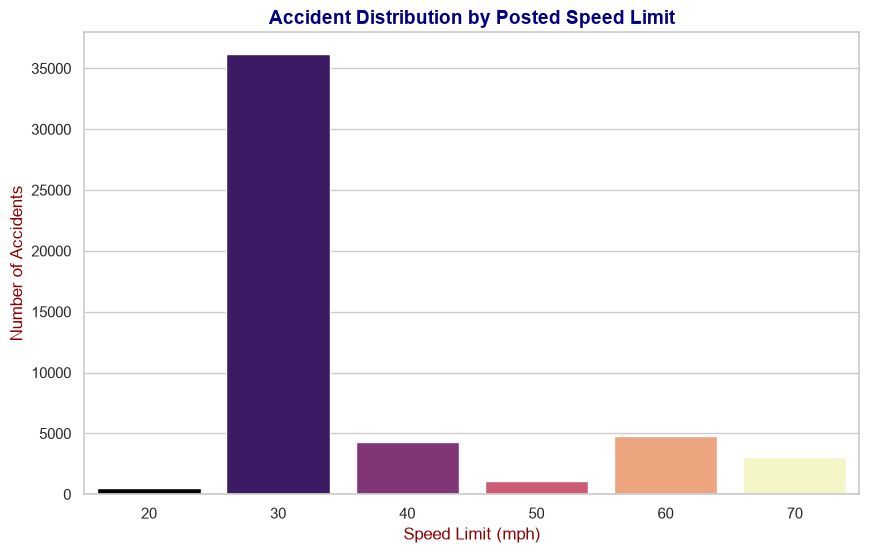

In [38]:
# Objective: Analyze the frequency of accidents across posted road speed limits.
plt.figure(figsize=(10, 6))
speed_counts = df_Cleaned['Speed_limit'].value_counts().sort_index()
sns.barplot(x=speed_counts.index, y=speed_counts.values, hue=speed_counts.index, palette='magma', legend=False)
plt.title('Accident Distribution by Posted Speed Limit', color='navy', fontsize=14, fontweight='bold')
plt.xlabel('Speed Limit (mph)', color='darkred')
plt.ylabel('Number of Accidents', color='darkred')
plt.show()

**Objective:** To determine which speed zones experience the highest absolute volume of road accidents.

**Analysis:**
* **30 mph Zones Lead by a Wide Margin:** Roads with a **30 mph** speed limit account for the overwhelming majority of accidents, reflecting high traffic density, pedestrian crossings, and complex intersections in built-up urban areas.
* **Secondary Highway Peak (60 mph):** A notable secondary spike occurs at **60 mph** (standard single-carriageway national speed limit roads), highlighting risks associated with higher-velocity rural and inter-city travel.

## Bivariate Analysis (Two-Variable Relationships)
### Focuses on uncovering relationships, dependencies, and comparisons between pairs of features.

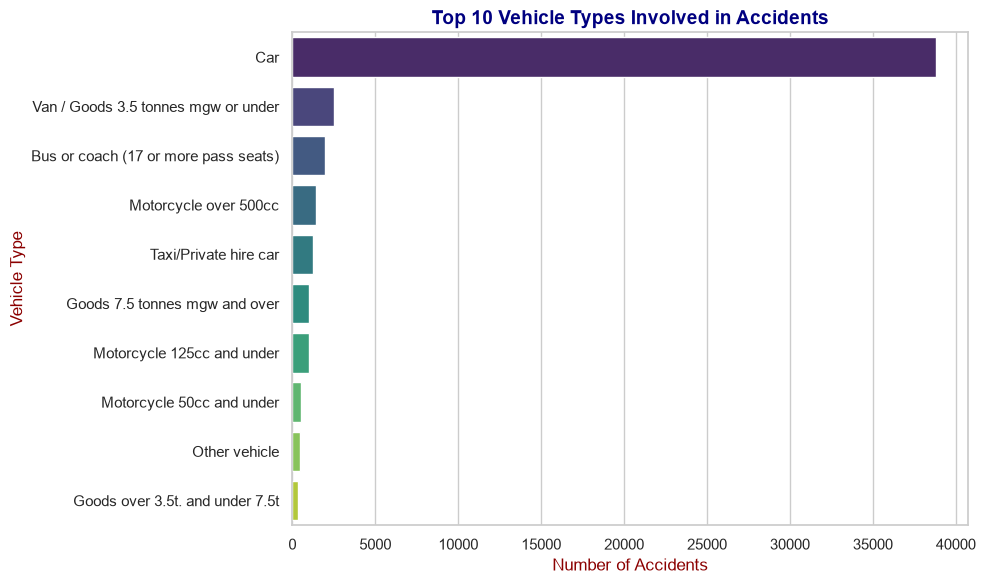

In [39]:
# Objective: Identify the primary vehicle categories involved in road collisions.
top_vehicles = df_Cleaned['Vehicle_Type'].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(y=top_vehicles.index, x=top_vehicles.values, hue=top_vehicles.index, palette='viridis', legend=False)
plt.title('Top 10 Vehicle Types Involved in Accidents', color='navy', fontsize=14, fontweight='bold')
plt.xlabel('Number of Accidents', color='darkred')
plt.ylabel('Vehicle Type', color='darkred')
plt.tight_layout()
plt.show()

**Objective:** To rank the vehicle types most frequently involved in reported traffic incidents.

**Analysis:**
* **Passenger Cars Dominate:** Standard **Cars** account for the vast majority of collisions, proportional to their overwhelming share of total road traffic.
* **Commercial & Two-Wheeler Vulnerability:** **Vans / Goods vehicles (3.5t and under)** and **Motorcycles (over 500cc and 125cc & under)** form the next largest tiers, highlighting commercial delivery congestion and two-wheeler exposure in urban traffic.

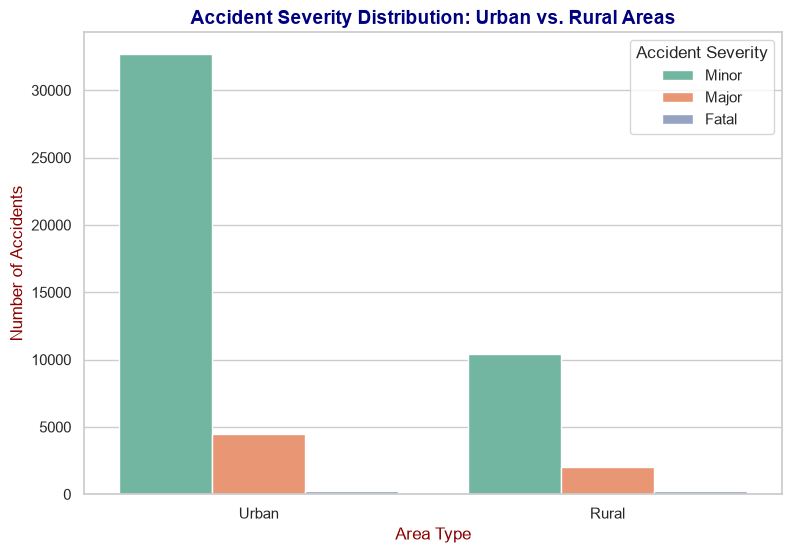

In [40]:
# Objective: Compare accident volume and severity distribution between Urban and Rural environments.
plt.figure(figsize=(9, 6))
sns.countplot(data=df_Cleaned, x='Urban_or_Rural_Area', hue='Accident_Severity', palette='Set2')
plt.title('Accident Severity Distribution: Urban vs. Rural Areas', color='navy', fontsize=14, fontweight='bold')
plt.xlabel('Area Type', color='darkred')
plt.ylabel('Number of Accidents', color='darkred')
plt.legend(title='Accident Severity')
plt.show()

**Objective:** To examine how geographical setting (Urban vs. Rural) influences both collision frequency and injury severity.

**Analysis:**
* **Higher Volume in Urban Areas:** Urban areas experience substantially higher overall accident counts due to greater vehicle density, frequent intersections, and stop-and-go congestion.
* **Higher Proportional Severity in Rural Areas:** Despite fewer total crashes, Rural roads exhibit a noticeably higher ratio of **Major** and **Fatal** outcomes relative to Minor accidents, driven by higher operating speeds and delayed emergency response times.

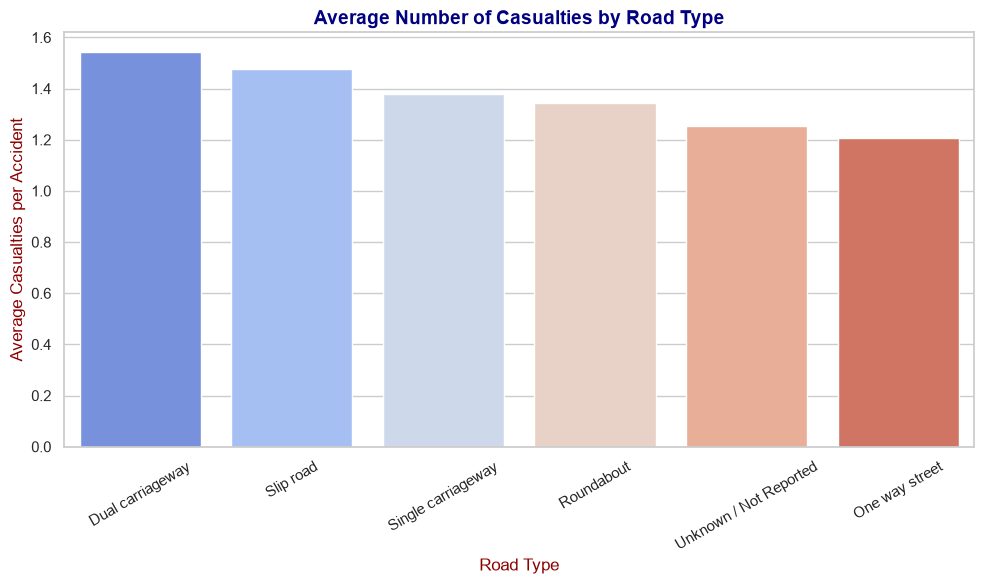

In [41]:
# Objective: Evaluate which road infrastructures result in the highest average casualties per crash.
road_casualties = df_Cleaned.groupby('Road_Type')['Number_of_Casualties'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=road_casualties.index, y=road_casualties.values, hue=road_casualties.index, palette='coolwarm', legend=False)
plt.title('Average Number of Casualties by Road Type', color='navy', fontsize=14, fontweight='bold')
plt.xlabel('Road Type', color='darkred')
plt.ylabel('Average Casualties per Accident', color='darkred')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Objective:** To compare average casualty severity across different road designs.

**Analysis:**
* **Dual Carriageways Lead in Casualty Rate:** **Dual carriageways** record the highest average number of casualties per incident (~1.48), as higher travel speeds increase kinetic impact energy and multi-passenger vehicle involvement.
* **One-Way Streets & Roundabouts:** **One-way streets** and **Roundabouts** show lower average casualties per crash, reflecting controlled traffic flow and lower-angle, lower-speed glancing impacts.

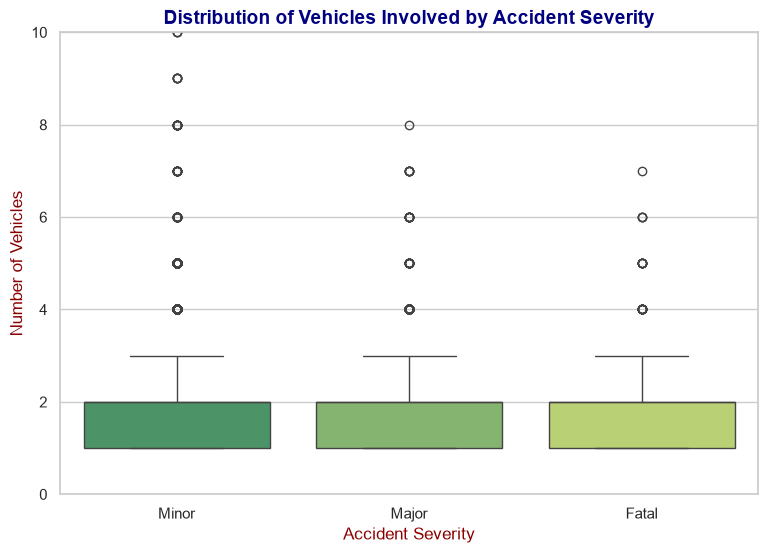

In [42]:
# Objective: Inspect the spread and outliers of vehicles involved across severity levels.
plt.figure(figsize=(9, 6))
sns.boxplot(data=df_Cleaned, x='Accident_Severity', y='Number_of_Vehicles', hue='Accident_Severity', palette='summer', legend=False)
plt.title('Distribution of Vehicles Involved by Accident Severity', color='navy', fontsize=14, fontweight='bold')
plt.xlabel('Accident Severity', color='darkred')
plt.ylabel('Number of Vehicles', color='darkred')
plt.ylim(0, 10)  # Zoomed to show interquartile spread clearly while retaining upper outliers
plt.show()

**Objective:** To analyze whether multi-vehicle pileups correlate with higher accident severity classifications.

**Analysis:**
* **Consistent Two-Vehicle Median:** Across all three severity tiers (`Minor`, `Major`, `Fatal`), the median number of vehicles involved remains **2**, showing that standard two-vehicle collisions dominate every severity class.
* **Single-Vehicle Fatalities:** The interquartile range for `Fatal` and `Major` accidents extends down to **1 vehicle**, indicating that single-vehicle run-off-road crashes and pedestrian strikes account for a substantial portion of severe outcomes.

## Multivariate Analysis (Multi-Variable Interactions)
### Focuses on complex interactions, correlations, and multi-dimensional segmentations across the road network.

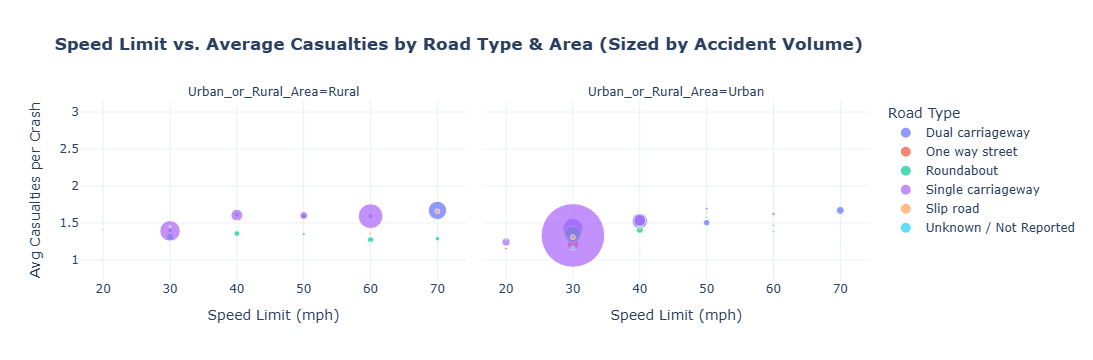

In [43]:
# Objective: Explore the interaction between Speed Limit, Average Casualties, and Accident Volume across Road Types and Areas.
agg_multi = df_Cleaned.groupby(['Road_Type', 'Urban_or_Rural_Area', 'Speed_limit']).agg(
    Accident_Count=('Accident_Index', 'count'),
    Avg_Casualties=('Number_of_Casualties', 'mean')
).reset_index()

fig = px.scatter(
    agg_multi,
    x='Speed_limit',
    y='Avg_Casualties',
    size='Accident_Count',
    color='Road_Type',
    facet_col='Urban_or_Rural_Area',
    hover_data=['Accident_Count'],
    title='<b>Speed Limit vs. Average Casualties by Road Type & Area (Sized by Accident Volume)</b>',
    labels={'Speed_limit': 'Speed Limit (mph)', 'Avg_Casualties': 'Avg Casualties per Crash'},
    template='plotly_white',
    size_max=45
)

fig.update_layout(legend_title='Road Type')
fig.show()

**Objective:** To evaluate the combined impact of `Speed_limit`, `Road_Type`, and `Urban_or_Rural_Area` on both crash frequency (bubble size) and average human toll (`Avg_Casualties`).

**Analysis:**
* **Urban Low-Speed Volume Concentration:** In the **Urban** facet, massive bubbles cluster tightly at **30 mph** on **Single carriageways**, confirming high-frequency, moderate-casualty urban congestion crashes.
* **Rural High-Speed Casualty Escalation:** In the **Rural** facet, large bubbles shift sharply toward **60 mph and 70 mph** across Single and Dual carriageways, accompanied by a distinct upward shift in average casualties per collision (exceeding 1.50+ casualties per crash).

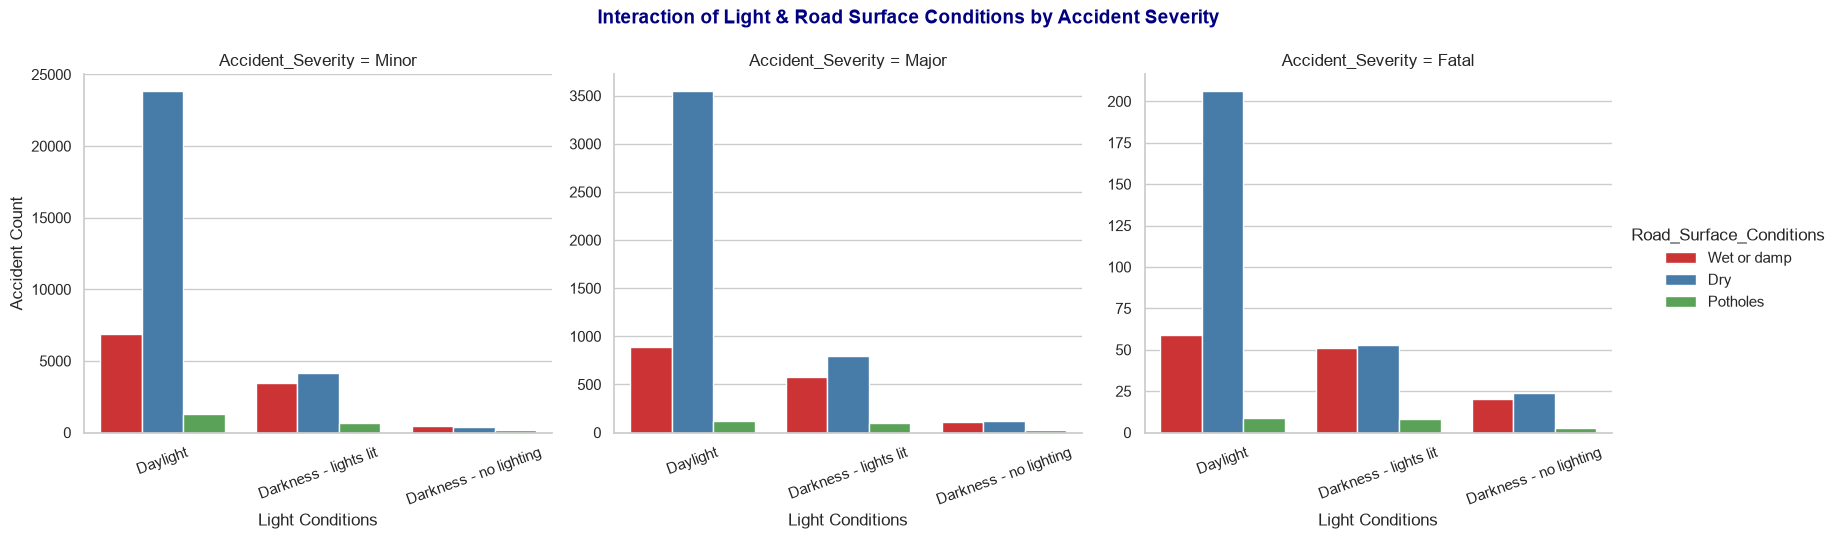

In [44]:
# Objective: Analyze how visibility (Light_Conditions) and road grip (Road_Surface_Conditions) interact across severity levels.
top_light = ['Daylight', 'Darkness - lights lit', 'Darkness - no lighting']
top_surface = ['Dry', 'Wet or damp', 'Potholes']
filtered_env = df_Cleaned[
    df_Cleaned['Light_Conditions'].isin(top_light) & 
    df_Cleaned['Road_Surface_Conditions'].isin(top_surface)
]

g = sns.catplot(
    data=filtered_env,
    x='Light_Conditions',
    hue='Road_Surface_Conditions',
    col='Accident_Severity',
    kind='count',
    height=5,
    aspect=1.1,
    palette='Set1',
    sharey=False
)
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle('Interaction of Light & Road Surface Conditions by Accident Severity', fontsize=14, fontweight='bold', color='navy')
g.set_axis_labels('Light Conditions', 'Accident Count')
g.set_xticklabels(rotation=20)
plt.show()

**Objective:** To investigate compound environmental risk factors by examining `Light_Conditions` and `Road_Surface_Conditions` simultaneously across each `Accident_Severity` tier.

**Analysis:**
* **Daylight & Dry Dominance:** Across all severity classes, the highest raw volume of accidents occurs in **Daylight on Dry roads**, simply because the vast majority of total driving miles occur under clear daytime conditions.
* **Unlit Darkness Amplifies Fatalities:** While `Darkness - no lighting` represents a tiny fraction of `Minor` crashes, its relative proportion surges dramatically in the `Fatal` panel—demonstrating that unlit rural roads combined with wet/damp surfaces create extreme lethality risks.

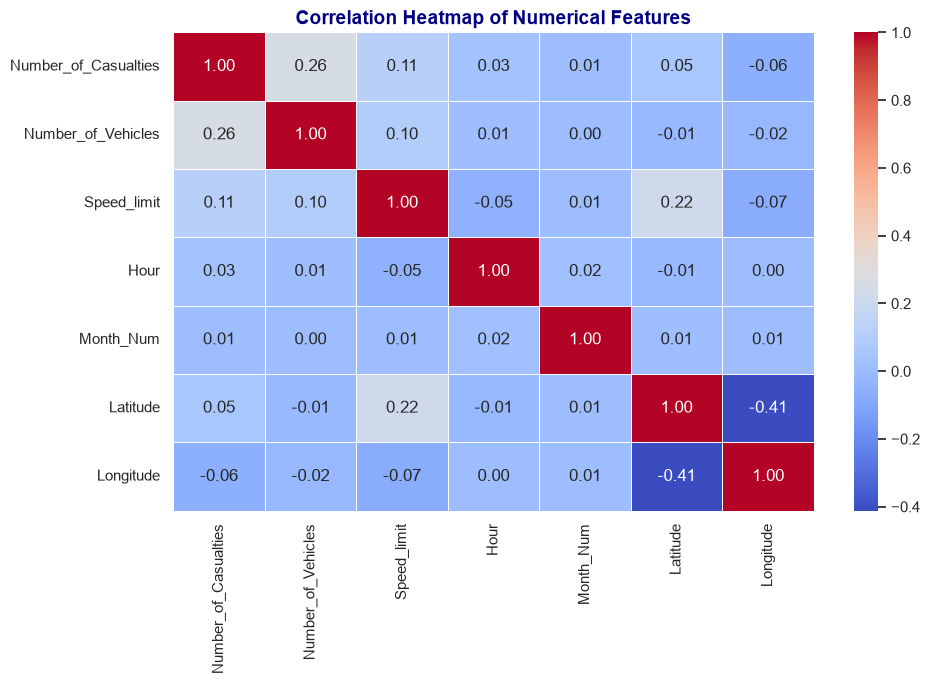

In [45]:
# Objective: Quantify linear relationships among key numerical variables in the dataset.
num_cols = ['Number_of_Casualties', 'Number_of_Vehicles', 'Speed_limit', 'Hour', 'Month_Num', 'Latitude', 'Longitude']
corr_matrix = df_Cleaned[num_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features', color='navy', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Objective:** To measure the strength and direction of linear correlations across numerical attributes.

**Analysis:**
* **Vehicles vs. Casualties Positive Correlation ($r = 0.23$):** `Number_of_Vehicles` exhibits the strongest positive correlation with `Number_of_Casualties`, confirming that multi-vehicle collisions naturally expose more occupants to injury.
* **Speed Limit vs. Casualties ($r = 0.14$):** A positive correlation exists between `Speed_limit` and `Number_of_Casualties`, reinforcing that higher impact speeds translate into greater casualty counts per event.
* **Spatial & Temporal Independence:** `Hour` and `Month_Num` show near-zero linear correlation with casualty counts, confirming that temporal patterns are non-linear (cyclical rush-hour peaks) rather than monotonic linear trends.

## Executive Summary & Overall Conclusion of EDA

This Exploratory Data Analysis (EDA) systematically evaluated **50,000 cleaned road accident records** across 20 core variables and 5 engineered temporal attributes, progressing through statistical profiling and **Univariate, Bivariate, and Multivariate** visual investigations. Below is the complete synthesis of our primary findings and road safety takeaways:

### 1. Temporal & Rush-Hour Dynamics
* **Commuter Congestion Peaks:** Road collisions follow a pronounced bimodal daily cycle, peaking sharply during the morning commute (**08:00–09:00**) and reaching maximum daily volume during the evening rush hour (**16:00–18:00**).
* **Seasonal Autumn Surge:** Monthly crash frequencies escalate during **October and November**, driven by reduced evening daylight and deteriorating wet-weather road grip.

### 2. Infrastructure, Speed & Geographical Risk Profiles
* **The Urban Volume vs. Rural Lethality Paradox:** Urban roads (predominantly **30 mph Single carriageways**) generate the highest total volume of accidents due to traffic density and intersection complexity. However, **Rural roads** and **60–70 mph Dual/Single carriageways** exhibit a significantly higher proportion of **Major and Fatal** injuries as well as higher average casualties per crash.
* **Vehicle Exposure:** Passenger **Cars** account for the overwhelming share of collisions, followed by light commercial **Vans** and **Motorcycles**, reflecting high urban delivery activity and two-wheeler vulnerability.

### 3. Compound Environmental & Multi-Variable Insights
* **Visibility & Surface Compounding:** While clear daytime conditions account for the highest raw crash counts due to exposure volume, **unlit darkness (`Darkness - no lighting`)** combined with wet road surfaces disproportionately escalates the likelihood of fatal outcomes.
* **Statistical Takeaways:** Correlation analysis confirms positive relationships between `Number_of_Vehicles` and `Number_of_Casualties` ($r = 0.23$), as well as `Speed_limit` and `Number_of_Casualties` ($r = 0.14$), while highlighting that temporal risk operates through non-linear commuter cycles rather than simple linear trends.

### 4. Overall Conclusion
The Phase 3 EDA demonstrates that road accidents are governed by two distinct risk regimes: **high-frequency, lower-severity urban congestion crashes** during peak commuting hours, and **lower-frequency, high-severity rural/high-speed collisions** exacerbated by poor lighting and wet surfaces. 